# 3.2 y 3.3 VaR al 95% con GAN y con Monte Carlo
Ambos modelos usan la misma ventana (500 días previos), generan **500 escenarios** de rendimientos a 1 día y calculan el VaR sobre el portafolio equiponderado. Los resultados de los 20 días del backtest vienen de `src/02_var_redes_gan_propio.py` y `src/03_var_montecarlo.py`.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import config, utils, plotstyle
plotstyle.apply()
pd.options.display.float_format = "{:.4f}".format
r = utils.load_returns()
train = utils.train_window(r.values, 0)           # 500 días previos al primer día de backtest
hist_port = utils.portfolio_return(train)
gan_s = pd.read_csv(config.RESULTS_DIR / "escenarios_gan_t0.csv").values
mc_s = pd.read_csv(config.RESULTS_DIR / "escenarios_mc_t0.csv").values
gan_port, mc_port = utils.portfolio_return(gan_s), utils.portfolio_return(mc_s)
print(f"{len(gan_s)} escenarios GAN, {len(mc_s)} escenarios Monte Carlo")

500 escenarios GAN, 500 escenarios Monte Carlo


## Entrenamiento de la GAN
Pérdidas del discriminador (D) y del generador (G) en la primera ventana. En una GAN sana ninguna pérdida colapsa a cero: ambas redes siguen compitiendo.

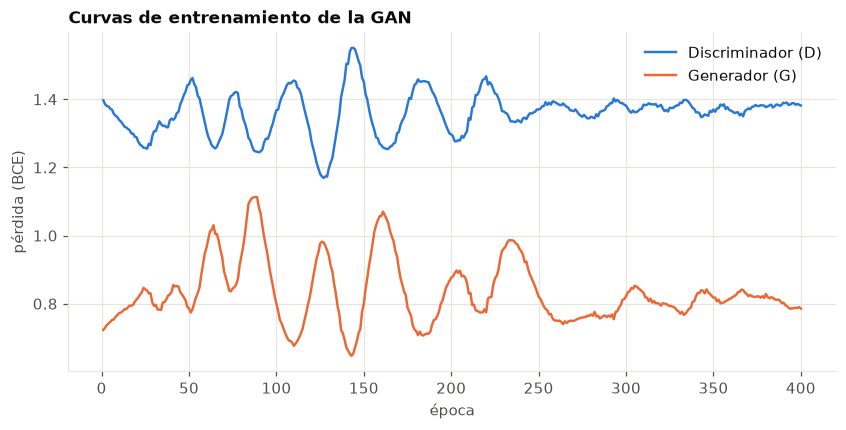

In [2]:
h = pd.read_csv(config.RESULTS_DIR / "gan_perdidas_t0.csv")
fig, ax = plt.subplots()
ax.plot(h["epoch"], h["loss_D"], color=plotstyle.BLUE, label="Discriminador (D)")
ax.plot(h["epoch"], h["loss_G"], color=plotstyle.ORANGE, label="Generador (G)")
ax.set_xlabel("época"); ax.set_ylabel("pérdida (BCE)"); ax.set_title("Curvas de entrenamiento de la GAN"); ax.legend()
plotstyle.save(fig, "02_gan_perdidas"); plt.show()

## ¿Qué tan bien reproduce cada modelo la distribución del portafolio?

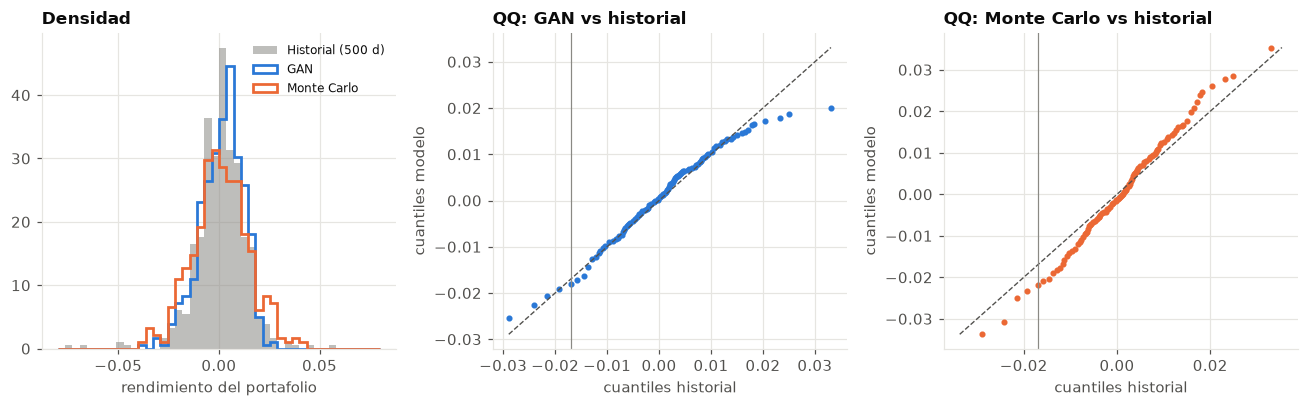

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
bins = np.linspace(-0.08, 0.08, 45)
ax = axes[0]
ax.hist(hist_port, bins=bins, density=True, color=plotstyle.C_HIST, alpha=0.55, label="Historial (500 d)")
for s, c, lab in [(gan_port, plotstyle.C_GAN, "GAN"), (mc_port, plotstyle.C_MC, "Monte Carlo")]:
    ax.hist(s, bins=bins, density=True, histtype="step", color=c, lw=1.8, label=lab)
ax.set_title("Densidad"); ax.set_xlabel("rendimiento del portafolio"); ax.legend(fontsize=8)
qs = np.linspace(0.01, 0.99, 99)
for ax, s, c, lab in [(axes[1], gan_port, plotstyle.C_GAN, "GAN"), (axes[2], mc_port, plotstyle.C_MC, "Monte Carlo")]:
    qh, qm = np.quantile(hist_port, qs), np.quantile(s, qs)
    ax.scatter(qh, qm, s=9, color=c); lim = [min(qh.min(), qm.min()), max(qh.max(), qm.max())]
    ax.plot(lim, lim, color=plotstyle.INK2, lw=0.9, ls="--")
    ax.axvline(-utils.var_es(hist_port)[0], color=plotstyle.C_HIST, lw=0.8)
    ax.set_title(f"QQ: {lab} vs historial"); ax.set_xlabel("cuantiles historial"); ax.set_ylabel("cuantiles modelo")
plt.tight_layout(); plotstyle.save(fig, "02_distribuciones"); plt.show()

In [4]:
rows = {}
for name, p in [("Historial (500 d)", hist_port), ("GAN", gan_port), ("Monte Carlo", mc_port)]:
    var, es = utils.var_es(p)
    lo, hi = utils.bootstrap_var_ci(p) if name != "Historial (500 d)" else (np.nan, np.nan)
    rows[name] = {"media": p.mean(), "desv.": p.std(), "asimetría": stats.skew(p),
                  "curtosis exceso": stats.kurtosis(p), "VaR 95%": var, "IC95% inf": lo, "IC95% sup": hi, "ES 95%": es}
pd.DataFrame(rows).T

,media,desv.,asimetría,curtosis exceso,VaR 95%,IC95% inf,IC95% sup,ES 95%
Historial (500 d),0.0011,0.0133,0.3469,11.4105,0.0169,NaN,NaN,0.0292
GAN,0.0013,0.0105,-0.5279,0.2457,0.0181,0.0162,0.0200,0.0233
Monte Carlo,0.0008,0.0141,-0.0022,0.1174,0.0219,0.0203,0.0241,0.0287


In [5]:
def offdiag(c): return pd.Series({"NVDA-JPM": c[0, 1], "NVDA-XOM": c[0, 2], "JPM-XOM": c[1, 2]})
pd.DataFrame({"Historial": offdiag(np.corrcoef(train.T)), "GAN": offdiag(np.corrcoef(gan_s.T)),
              "Monte Carlo": offdiag(np.corrcoef(mc_s.T))}).rename_axis("correlación")

,Historial,GAN,Monte Carlo
correlación,,,
NVDA-JPM,0.3190,0.2765,0.4077
NVDA-XOM,0.0011,-0.1639,0.0142
JPM-XOM,0.1497,0.0043,0.1765


## VaR a lo largo de los 20 días de prueba

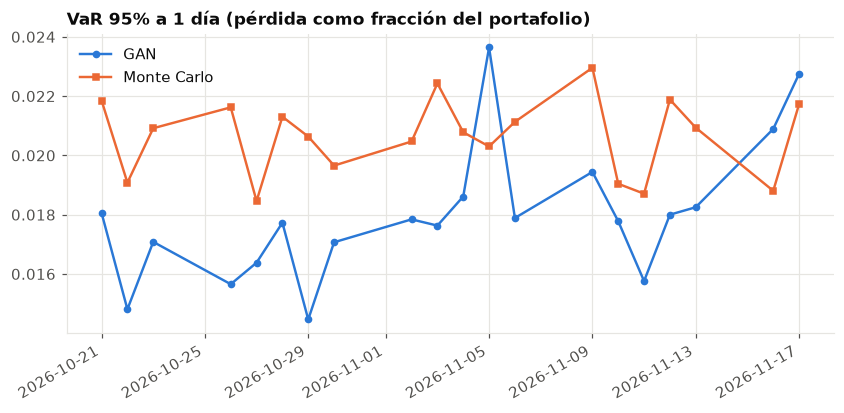

,count,mean,std,min,25%,50%,75%,max
VaR GAN,20.0000,0.0180,0.0023,0.0145,0.0169,0.0178,0.0183,0.0236
VaR Monte Carlo,20.0000,0.0206,0.0013,0.0185,0.0195,0.0208,0.0216,0.0230
ES GAN,20.0000,0.0228,0.0024,0.0202,0.0209,0.0222,0.0236,0.0298
ES Monte Carlo,20.0000,0.0259,0.0019,0.0224,0.0249,0.0253,0.0273,0.0292


In [6]:
g = pd.read_csv(config.RESULTS_DIR / "var_gan.csv", index_col=0, parse_dates=True)
m = pd.read_csv(config.RESULTS_DIR / "var_montecarlo.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots()
ax.plot(g.index, g["var_95"], marker="o", ms=4, color=plotstyle.C_GAN, label="GAN")
ax.plot(m.index, m["var_95"], marker="s", ms=4, color=plotstyle.C_MC, label="Monte Carlo")
ax.set_title("VaR 95% a 1 día (pérdida como fracción del portafolio)"); ax.legend()
fig.autofmt_xdate(); plotstyle.save(fig, "02_var_20dias"); plt.show()
pd.DataFrame({"VaR GAN": g["var_95"], "VaR Monte Carlo": m["var_95"], "ES GAN": g["es_95"], "ES Monte Carlo": m["es_95"]}).describe().T

## Observaciones (VaR en t0, primer día del backtest)
- **VaR 95%:** historial 1.69%, GAN 1.81% (IC95% 1.62%–2.00%), Monte Carlo 2.19% (IC95% 2.03%–2.41%). El IC de la GAN contiene al valor histórico; el del Monte Carlo no.
- **Monte Carlo sobrestima el VaR respecto al historial.** Es coherente con datos de colas pesadas y centro apuntado: una normal con la misma desviación reparte más masa en la zona del 5% que la distribución real, que concentra su riesgo más allá del VaR. Por eso el ES histórico (2.92%) queda cerca del de Monte Carlo (2.87%).
- **La GAN subestima dispersión y colas:** desviación 1.05% frente a 1.33% histórica, curtosis en exceso 0.25 frente a 11.4, y ES de 2.33% frente a 2.92%. Con 500 observaciones la GAN aprende el cuerpo de la distribución pero no los eventos extremos.
- **Dependencia:** la GAN distorsiona las correlaciones (NVDA-XOM -0.16 frente a 0.00; JPM-XOM 0.00 frente a 0.15). El Monte Carlo las reproduce mejor por construcción (usa la matriz de covarianza muestral).
- **En los 20 días de prueba** el VaR medio es 1.80% (GAN) y 2.06% (Monte Carlo); la GAN es más variable día a día (rango 1.45%–2.36%) porque se re-entrena cada vez.